In [1]:
import pyswarms as ps
from pyswarms.utils.plotters import plot_cost_history, plot_contour, plot_surface
import axelrod as axl
from axelrod.action import Action, actions_to_str
from axelrod.player import Player
from axelrod.strategy_transformers import (
    FinalTransformer,
    TrackHistoryTransformer,
)
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np
from collections import Counter
import pandas as pd
from math import exp
import numpy as np
import matplotlib.pyplot as plt

In [2]:
C, D = Action.C, Action.D

class FuzzyMethods():
    @staticmethod
    def sigmoid(x, center, scale=10):
        return 1 / (1 + exp(-scale * (x - center)))
    
    @staticmethod
    def fuzzy_gate(mu_D, d_thresh, mu_C, c_thresh):
            d_condition = FuzzyMethods.sigmoid(mu_D, center=d_thresh)
            c_condition = 1 - FuzzyMethods.sigmoid(mu_C, center=c_thresh)
    
            w1 = d_condition * c_condition
            
            return w1
    
    @staticmethod
    def calc_cooperation(self, opponent):
        return (Counter(opponent.history)[C])/len(opponent.history)*100
    
    @staticmethod
    def calc_adaptivity(self, opponent):
        adapCounter = 0
        adapReaction = 0

        if(len(self.history) < 3): 
            return 0
        
        for i in range(3, len(self.history)):
            if (self.history[i-3] == C and self.history[i-2] == D):
                adapCounter += 1
                if (opponent.history[i-1] == D):
                    adapReaction += 1
                elif (self.history[i-1] == D and opponent.history[i] == D):
                    adapReaction += 0.5
            elif (self.history[i-3] == D and self.history[i-2] == C):
                adapCounter += 1
                if (opponent.history[i-1] == C):
                    adapReaction += 1
                elif (self.history[i-1] == C and opponent.history[i] == C):
                    adapReaction += 0.5

        if adapCounter == 0:
            return 0
        
        return adapReaction/adapCounter*100

    
    @staticmethod
    def calc_forgiveness(self, opponent):
        DCounter = 0
        punishmentCounter = 0

        for i in range(0, len(self.history)-1):
            if(self.history[i] == D):
                DCounter += 1
                for j in range (i+1, len(opponent.history)):
                    if(opponent.history[j] == C):
                        break
                    else:
                        punishmentCounter += 1
              

        if punishmentCounter > 0:
            return DCounter/punishmentCounter*100
        else:
            return 100
    
    @staticmethod
    def calc_stochastic(self, opponent):
        patterns = [
            [C, C, C],
            [C, C, D],
            [C, D, C],
            [C, D, D],
            [D, C, C],
            [D, C, D],
            [D, D, C],
            [D, D, D]
        ]

        non_stochasticCounter = 0
        patternPlayedCounter = 0

        for p in patterns:
            opponentsReactions = []
            for i in range(0, len(self.history)-3):
                if ([self.history[i], self.history[i+1], self.history[i+2]] == p):
                    opponentsReactions.append([opponent.history[i+1], opponent.history[i+2], opponent.history[i+3]])
            
            unique_patterns = len(set(tuple(sub) for sub in opponentsReactions))

            if(len(opponentsReactions) > 0):
                non_stochasticCounter += 0 if unique_patterns == 1 else unique_patterns
                patternPlayedCounter += len(opponentsReactions)
        
        if patternPlayedCounter == 0:
            return 0
        
        return non_stochasticCounter/patternPlayedCounter*100

In [3]:
def build_player(params): 
    d_abc = np.sort(np.round(params[:3]))   # round only if you want integer vertices
    c_abc = np.sort(np.round(params[3:]))

    class FSOptimized(Player):

        name = "FuzzySugeno"
        classifier = {
            "memory_depth": float("inf"),
            "stochastic": False,
            "long_run_time": False,
            "inspects_source": False,
            "manipulates_source": False,
            "manipulates_state": False,
        }

        cooperation = ctrl.Antecedent(np.arange(0, 100, 1), 'cooperation')
        adaptivity = ctrl.Antecedent(np.arange(0, 100, 1), 'adaptivity')
        forgiveness = ctrl.Antecedent(np.arange(0, 100, 1), 'forgiveness')
        stochastic = ctrl.Antecedent(np.arange(0, 100, 1), 'stochastic')

        cooperation.automf(names=["low", "medium", "high"])
        adaptivity.automf(names=["no", "yes"])
        forgiveness.automf(names=["low", "medium", "high"])
        forgiveness['low'] = fuzz.gaussmf(forgiveness.universe, 0, 25)
        forgiveness['medium'] = fuzz.trimf(forgiveness.universe, [25, 50, 75])
        stochastic.automf(names=["none", "sometimes", "always"])

        resulting_strategy = ctrl.Consequent(np.arange(0, 100, 1),'resulting_strategy')
        resulting_strategy['D'] = fuzz.trimf(resulting_strategy.universe, d_abc)
        resulting_strategy['C'] = fuzz.trimf(resulting_strategy.universe, c_abc)

        rule1 = ctrl.Rule(cooperation['high'] & adaptivity['no'] & (forgiveness['medium'] | forgiveness['high']), resulting_strategy['D'])
        rule2 = ctrl.Rule(forgiveness['low'] & cooperation['high'], resulting_strategy['C'])
        rule3 = ctrl.Rule(stochastic['always'] | adaptivity['no'], resulting_strategy['D'])
        rule4 = ctrl.Rule(cooperation['low'] | (cooperation['medium'] & forgiveness['low']), resulting_strategy['D'])
        rule5 = ctrl.Rule(cooperation['medium'] & forgiveness['medium'] & adaptivity['yes'], resulting_strategy['C'])

        strategy_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
        chosen_strategy = ctrl.ControlSystemSimulation(strategy_ctrl)

        h = {'Name':'', 'Fuzzy' : [], 'Opponent': []}

        forgiveness_index = 0
        stochastic_index = 0
        first_time = True
    
        def strategy(self, opponent: Player) -> Action:

            if(len(self.history) == 0 or D not in opponent.history):
                return C
            
            else:
                coop = FuzzyMethods.calc_cooperation(self, opponent)
                adap = FuzzyMethods.calc_adaptivity(self, opponent)
                forg = FuzzyMethods.calc_forgiveness(self, opponent)
                stoch = FuzzyMethods.calc_stochastic(self, opponent)

                self.chosen_strategy.input['cooperation'] = coop
                self.chosen_strategy.input['adaptivity'] = adap
                self.chosen_strategy.input['forgiveness'] = forg
                self.chosen_strategy.input['stochastic'] = stoch
                
                self.chosen_strategy.compute()

                d_membership = fuzz.interp_membership(self.resulting_strategy.universe, self.resulting_strategy['D'].mf, self.chosen_strategy.output['resulting_strategy'])
                c_membership = fuzz.interp_membership(self.resulting_strategy.universe, self.resulting_strategy['C'].mf, self.chosen_strategy.output['resulting_strategy'])

                output = FuzzyMethods.fuzzy_gate(d_membership, 0.5, c_membership, 0.5)

                if(output > 0.5):
                    return D
            
            return C
    return FSOptimized()

In [4]:
def fitness_function(x):
    costs = []
    for params in x:                      # params = [d_thresh, c_thresh]
        results = axl.Tournament(
            players=[build_player(params)] + [p() for p in axl.stewart_plotkin_strategies],
            turns=200,
        ).play(progress_bar=False)
        costs.append(-np.mean(results.normalised_scores[0]))   # negate: pyswarms minimizes
    return np.array(costs)

In [5]:
options = {'c1': 1.5, 'c2': 1.5, 'w': 0.7}
bounds = (np.zeros(6), np.full(6, 99))

init_pos =np.array(
    [
        [0, 25, 50, 35, 75, 99],
        [0, 20, 30, 20, 50, 99],
         [0, 25, 50, 50, 75, 99],
         [0, 10, 30, 20, 50, 99],
         [0, 15, 30, 30, 50, 99],
         [0, 30, 40, 15, 50, 99],
         [0, 20, 35, 75, 90, 99],
         [0, 25, 75, 20, 50, 99],
         [0, 25, 75, 65, 80, 99]
      ], dtype=float)

optimizer = ps.single.GlobalBestPSO(n_particles=9, 
                                    dimensions=6, 
                                    options=options, 
                                 init_pos=init_pos, bounds=bounds)

cost, pos = optimizer.optimize(fitness_function,
                                 iters=50)

2026-11-27 08:05:00,118 - pyswarms.single.global_best - INFO - Optimize for 50 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.7}
pyswarms.single.global_best: 100%|██████████|50/50, best_cost=-2.77
2026-11-27 11:14:33,594 - pyswarms.single.global_best - INFO - Optimization finished | best cost: -2.7657857142857143, best pos: [ 0.29098615 19.78168941 33.97680729 57.9353526  49.86308062 74.97889714]


In [6]:
print("best score:", -cost)
print("D triangle:", np.sort(np.round(pos[:3])))
print("C triangle:", np.sort(np.round(pos[3:])))    

best score: 2.7657857142857143
D triangle: [ 0. 20. 34.]
C triangle: [50. 58. 75.]


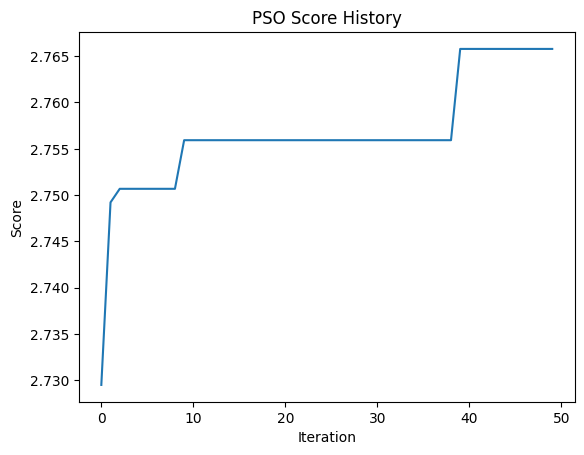

In [7]:
# plot_cost_history(optimizer.cost_history)
plot_h = []
for x in optimizer.cost_history:
    plot_h.append(-x)  # flip sign back for the real score
plt.plot(plot_h)
plt.xlabel('Iteration')
plt.ylabel('Score')
plt.title('PSO Score History')
plt.show()